In [1]:
import sys; sys.path.insert(0, "../src")

from protgen.data import ProteinDataset
from protgen.models.transformer_freeze import load_frozen_transformer
from protgen.models.classification_guidance import FamilyHead

In [2]:
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score

In [3]:
weights = "../hydra_results/training/classifier_11-27_14-01-14/hid256_d0.3/adamW_005/weights/best.pt"
hardware = "cpu"

In [4]:
train_data = ProteinDataset(path_to_data="../data/train.csv")
val_data = ProteinDataset(path_to_data="../data/val.csv")
test_data = ProteinDataset(path_to_data="../data/test.csv")

**Get the model**

In [5]:
best = torch.load(weights, map_location=hardware)
frozen_transformer = load_frozen_transformer("../"+best["frozen_weights"], hardware)
model = FamilyHead(frozen_transformer,
                   best["embedding_size"],
                   best["hidden_units"],
                   best["num_families"],
                   best["dropout"])
model.head.load_state_dict(best["weights"])
model.to(hardware)
model.eval()

c:\Users\marti\OneDrive\Documents\GitHub\02456-autoregressive-project\notebooks\../src\protgen\models\transformer_rocha.py:41: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layers, norm=nn.LayerNorm(embedding_size), num_layers=num_layers)


FamilyHead(
  (frozen_transformer): Transformer(
    (sinusoid_positional_encoding): SinusoidPositionalEncoding()
    (embedding): Embedding(23, 128, padding_idx=0)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-5): 6 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
          )
          (linear1): Linear(in_features=128, out_features=512, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
          (linear2): Linear(in_features=512, out_features=128, bias=True)
          (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
          (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
          (dropout1): Dropout(p=0.1, inplace=False)
          (dropout2): Dropout(p=0.1, inplace=False)
        )
      )
      (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
   

*HERE IS THE FULL ARCHITECTURE TRANSFORMER + GUID HEAD*

3.4 FFN MNIST - Source Inspiration for accuracy

In [6]:
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

In [7]:

############### ACCURACY FOR PARTIAL SEQUENCES AND FULL SEQUENCES ############################


sequence_length = [1, 5, 10, 20, 30, 40, 50, 60, 100, 120]
accuracies = []

for l in sequence_length:
    test_preds =  []
    test_targs= []
    with torch.no_grad():
        for x, x_shifted, y, length in test_loader:
            x = x.to(hardware)

            partial = x[:, :l + 1]          # <BOS> + the first n residues
            output = model(partial)         # (batch, n+1, 3)
            last = output[:, -1]            # the guess after the last residue seen

            preds = torch.max(last, 1)[1]
            test_preds += list(preds.cpu().numpy())
            test_targs += list(y.numpy())

    acc = accuracy_score(test_targs, test_preds)
    accuracies.append(acc)
    print("residues seen: %3i, accuracy: %f" % (l, acc))

residues seen:   1, accuracy: 0.332834
residues seen:   5, accuracy: 0.752124
residues seen:  10, accuracy: 0.884558
residues seen:  20, accuracy: 0.946527
residues seen:  30, accuracy: 0.965517
residues seen:  40, accuracy: 0.989505
residues seen:  50, accuracy: 0.995002
residues seen:  60, accuracy: 0.988506
residues seen: 100, accuracy: 0.998001
residues seen: 120, accuracy: 0.995002


*Plot and save it to results*

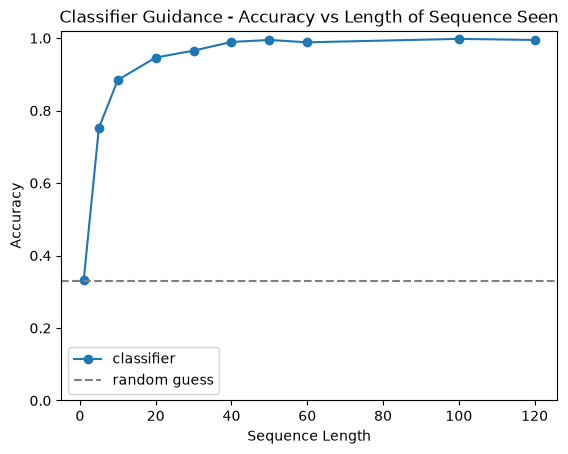

In [10]:
plt.figure()
plt.title("Classifier Guidance - Accuracy vs Length of Sequence Seen")
plt.plot(sequence_length, accuracies, "o-")
plt.axhline(0.33, color="grey", linestyle="--")
plt.xlabel("Sequence Length")
plt.ylabel("Accuracy")
plt.ylim(0, 1.02) # Report states that there is even dist of each family so in beginning should be random guess which is more or less 0.33
plt.legend(["classifier", "random guess"])
plt.savefig("../results/classifier_accuracy.png", dpi=150)